# Unused DFT/COSMO numbers

The model takes two numbers per molecule from the database: the gas-phase free energy $G$ (DFT, at 25 °C) and the solvation energy (MD, in EC and DEC). The database stores more. The first version of this notebook proposed three of them. Here each one gets one test and a verdict.

| # | Unused number | What it would change | Verdict |
|---|---|---|---|
| 1 | Gas-phase **enthalpy $H$** (so also entropy $S$) | $G$ follows the temperature instead of staying at its 25 °C value | **Worth adding.** No new fitted parameter. Only the heated spectra change |
| 2 | COSMO **H-bond donor strength** `sigma_hb_don` | Would predict the solvation corrections the fit finds | **No.** It does not follow the fitted corrections |
| 3 | COSMO **miscibility** (`lle`, $\ln\gamma^\infty$) | "Phase split" in pure EC or pure DEC | **No.** The flag is about mixing the pure liquids in bulk, not mM amounts in the 1:1 mixture. $\ln\gamma^\infty$ repeats the COSMO solvation energy |

One side result came out of test 2 (§3): **MD and COSMO-RS disagree on how much EC vs DEC matters**, by up to a factor of 100.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd() if (Path.cwd() / "kinetics").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO))
from demo.style import INK_MUTED, SERIES, apply_style
from kinetics.constants import EV_TO_KJ_MOL, HARTREE_TO_EV, KB_SI, EV_TO_J, T_STD_K
from kinetics.data import NETWORK, NETWORK_SPECIES, build_stoichiometric_matrix, format_equation, get_active_medium, get_solvent, load_snapshot
from kinetics.fitting.config import apply_fit_config
apply_style()

RUN = "thermo2_2pctH2O"            # the thermo fit that works (χ² 43.9/60); thermo3 failed
apply_fit_config(REPO / "notebooks" / "results" / RUN)
snap = load_snapshot(get_active_medium().path)
mol = {r["pipeline_id"]: r for r in snap["datasets"]}
cosmo = {}
for r in snap["cosmors"]["rows"]:
    cosmo.setdefault(r["solute_pipeline_id"], {})[r["solvent_pipeline_id"]] = r
md = {"EC": {}, "DEC": {}}
for r in snap["solvation"]:
    if get_solvent(r) in md:
        md[get_solvent(r)][r["raw_metadata"]["name"]] = r["delta_e_solv_kjmol"] / EV_TO_KJ_MOL   # eV

SP = list(NETWORK_SPECIES)
S = build_stoichiometric_matrix(NETWORK, SP)          # species × reactions
RXN = list(NETWORK)
EQ = {r: format_equation({"id": r, **NETWORK[r]}) for r in RXN}
KB_EV = KB_SI / EV_TO_J
per_rxn = lambda x: S.T @ np.array([x[s] for s in SP])   # Δ = products − reactants

## 1. Temperature: let $G$ follow $T$

**Now.** The model reads $G$ at 25 °C and keeps it fixed. At 80 °C it still uses the 25 °C value (`kinetics/thermo/gas.py`, `_stored_gibbs`).

**Proposal.** The database also stores $H$. Since $G = H - TS$, the entropy is $S = (H - G)/298.15\ \text{K}$, and then

$$\Delta G_\text{rxn}(T) = \Delta G_\text{rxn}(25\,°\text{C}) - (T - 298.15\ \text{K})\,\Delta S_\text{rxn}$$

There is nothing new to fit. A reaction that makes floppier molecules ($\Delta S > 0$) is favoured more when the tube is hot.

In [2]:
H = {s: mol[s]["enthalpy_eh"] * HARTREE_TO_EV for s in SP}
G = {s: mol[s]["gibbs_eh"] * HARTREE_TO_EV for s in SP}
dS = per_rxn({s: (H[s] - G[s]) / T_STD_K for s in SP})          # eV/K

def k_factor(T_C):
    T = T_C + 273.15
    return np.exp((T - T_STD_K) * dS / (KB_EV * T))          # K_eq(T) with this fix / K_eq(T) today

tab = pd.DataFrame({"reaction": [EQ[r] for r in RXN],
                    "ΔS (J/mol·K)": dS * EV_TO_KJ_MOL * 1e3,
                    **{f"K ×  at {t} °C": k_factor(t) for t in (30, 50, 80)}}, index=RXN)
tab.round(2)

,reaction,ΔS (J/mol·K),K × at 30 °C,K × at 50 °C,K × at 80 °C
R1,TMSPA + H2O ⇌ BMSPA + TMSOH,81.21,1.17,2.13,4.58
R2,BMSPA + H2O ⇌ MMSPA + TMSOH,61.33,1.13,1.77,3.15
R3,MMSPA + H2O ⇌ H3PO4 + TMSOH,34.35,1.07,1.38,1.90
R4,2 TMSOH ⇌ HMDSO + H2O,-53.35,0.90,0.61,0.37
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,27.86,1.06,1.30,1.69
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,7.98,1.02,1.08,1.16
R7,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,-19.01,0.96,0.84,0.70
R8,EC + TMSOH ⇌ TMSOEG + CO2,-8.78,0.98,0.92,0.85
R9,EC + TMSOEG ⇌ TMSOdiEG + CO2,-23.51,0.95,0.80,0.64


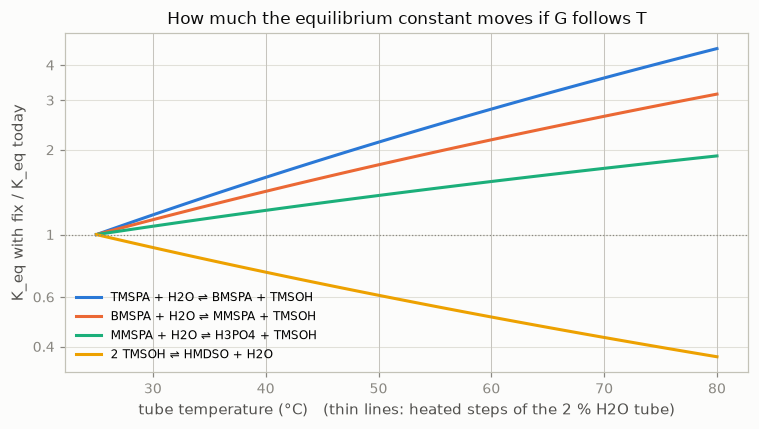

In [3]:
T = np.linspace(25, 80, 56)
fig, ax = plt.subplots(figsize=(7, 4))
for i, r in enumerate(["R1", "R2", "R3", "R4"]):
    j = RXN.index(r)
    ax.plot(T, [k_factor(t)[j] for t in T], color=SERIES[i], lw=2, label=EQ[r])
ax.axhline(1, color=INK_MUTED, lw=0.8, ls=":")
for t in (30, 40, 50, 60, 70, 80):
    ax.axvline(t, color=INK_MUTED, lw=0.5, alpha=0.4)
ax.set_yscale("log")
ax.set_yticks([0.4, 0.6, 1, 2, 3, 4]); ax.set_yticklabels(["0.4", "0.6", "1", "2", "3", "4"]); ax.minorticks_off()
ax.set_xlabel("tube temperature (°C)   (thin lines: heated steps of the 2 % H2O tube)")
ax.set_ylabel("K_eq with fix / K_eq today")
ax.set_title("How much the equilibrium constant moves if G follows T")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**What it means.**
- At 80 °C the first hydrolysis step (R1) is **×4.6** more favoured than the model says now. Condensation (R4, 2 TMSOH → HMDSO + H2O) is **×0.37**.
- At 30 °C the change is under 20 %.
- **Which data it touches:** only the heated steps (2 % H2O tube, 30–80 °C, about 17 min each; TMSOH probe tube, 80 °C). The thermo fit thermo2 uses room-temperature spectra only, so it **does not change**.
- **Limits.** (i) Only the gas-phase part follows $T$. The MD solvation energy stays at its 25 °C value. (ii) Gas-phase $S$ is RRHO from DFT. Every reaction here is 2 → 2 molecules, so the large translational entropy cancels and this error is small.
- **Code change:** in `_stored_gibbs`, return `G = H − T·S` instead of the stored `G`. About one line.

## 2. H-bond donor strength: does it predict the fitted corrections?

**Idea in v1.** Each hydrolysis step swaps a –SiMe₃ for an –OH. COSMO's `sigma_hb_don` grows with each –OH (TMSPA 0 → BMSPA 6.5 → MMSPA 14.3 → H3PO4 23.5). If the fitted solvation corrections followed it, two numbers (slope and offset) could replace one free correction per species.

**Test.** Compare at the reaction level, since only reaction differences mean anything (one species' correction can move if the others move with it). Plot Δ`sigma_hb_don` of each reaction against the correction the thermo2 fit adds to that reaction.

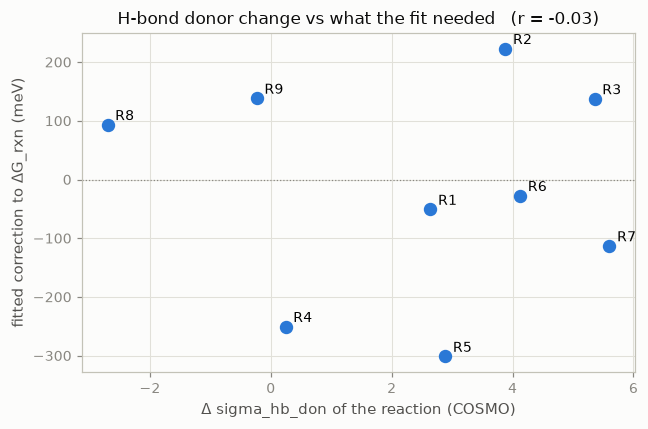

In [4]:
fit = json.loads(sorted((REPO / "notebooks/results" / RUN / "steps").glob("thermo__*_xi1.json"))[-1].read_text())
shift = {s: fit["species_shifts_eV"].get(s, 0.0) for s in SP}
d_don = per_rxn({s: mol[s]["sigma_hb_don"] for s in SP})
d_fit = per_rxn(shift)
r = np.corrcoef(d_don, d_fit)[0, 1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d_don, d_fit * 1e3, s=60, color=SERIES[0], zorder=3)
for x, y, name in zip(d_don, d_fit * 1e3, RXN):
    ax.annotate(name, (x, y), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.axhline(0, color=INK_MUTED, lw=0.8, ls=":")
ax.set_xlabel("Δ sigma_hb_don of the reaction (COSMO)")
ax.set_ylabel("fitted correction to ΔG_rxn (meV)")
ax.set_title(f"H-bond donor change vs what the fit needed   (r = {r:+.2f})")
plt.tight_layout(); plt.show()

**What it means.** The fit pushes reactions up and down with little relation to the H-bond change (see the r in the title). The descriptor does not explain the corrections, so it cannot replace them. **Not worth adding.**

v1 said "strongly correlating". That was true only for a different quantity (each species' MD EC − DEC solvation difference). It also used the thermo3 corrections, which come from the failed fit (χ² 4460).

## 3. Side result: does it matter whether the solvent is EC or DEC?

For each reaction: $\Delta G$ in pure EC minus $\Delta G$ in pure DEC, once from MD and once from COSMO-RS. If both methods were reliable, the bars would agree.

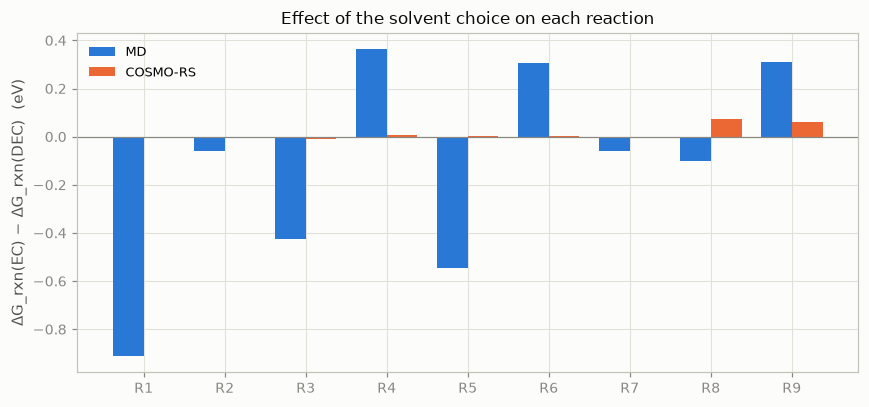

,reaction,MD (eV),COSMO (eV)
R1,TMSPA + H2O ⇌ BMSPA + TMSOH,-0.912,-0.005
R2,BMSPA + H2O ⇌ MMSPA + TMSOH,-0.059,-0.006
R3,MMSPA + H2O ⇌ H3PO4 + TMSOH,-0.424,-0.008
R4,2 TMSOH ⇌ HMDSO + H2O,0.366,0.008
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,-0.546,0.003
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,0.307,0.001
R7,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,-0.058,-0.001
R8,EC + TMSOH ⇌ TMSOEG + CO2,-0.103,0.075
R9,EC + TMSOEG ⇌ TMSOdiEG + CO2,0.309,0.062


In [5]:
KCAL_TO_EV = 4.184 / EV_TO_KJ_MOL
md_ecdec = per_rxn({s: md["EC"][s] - md["DEC"][s] for s in SP})
cos_ecdec = per_rxn({s: (cosmo[s]["EC"]["dg_solv_kcal_mol"] - cosmo[s]["DEC"]["dg_solv_kcal_mol"]) * KCAL_TO_EV for s in SP})

x = np.arange(len(RXN)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - w/2, md_ecdec, w, color=SERIES[0], label="MD")
ax.bar(x + w/2, cos_ecdec, w, color=SERIES[1], label="COSMO-RS")
ax.axhline(0, color=INK_MUTED, lw=0.8)
ax.set_xticks(x, RXN)
ax.set_ylabel("ΔG_rxn(EC) − ΔG_rxn(DEC)  (eV)")
ax.set_title("Effect of the solvent choice on each reaction")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"reaction": [EQ[r] for r in RXN], "MD (eV)": md_ecdec, "COSMO (eV)": cos_ecdec}, index=RXN).round(3)

**What it means.** COSMO-RS says EC or DEC barely matters (under 0.01 eV for R1–R7). MD says it moves R1 by 0.9 eV and R5 by 0.5 eV. Both cannot be right. These differences are what the mixing rule (64.5 % EC, 35.5 % DEC by mole) weights, so the size of the MD split matters for the model. This proposes nothing new to add. It is a question for the MD numbers (sampling noise?).

## Bottom line

**Add one thing: let $G$ follow temperature (§1).** It costs no parameters and changes only the heated spectra. The other two numbers do not help.